# Student Performance EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(suppress=True)
plt.style.use('default')
Path = __import__('pathlib').Path
Path('figures').mkdir(exist_ok=True)

In [2]:
students = pd.read_csv('student_performance.csv')
students['average_score'] = students[['math','english','science']].mean(axis=1).round(2)
students['performance_band'] = pd.cut(students['average_score'], bins=[-float('inf'),60,75,float('inf')], right=False, labels=['At Risk','Meeting','Exceeding'])
print(students.shape)
students.head()

(1200, 11)


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science,average_score,performance_band
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0,75.0,Exceeding
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0,92.0,Exceeding
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0,87.0,Exceeding
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0,82.0,Exceeding
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0,69.0,Meeting


## Structure

**Grain:** One row represents one student. The dataset contains 1,200 records. **Variables:** student_id, county, school_type, gender, attendance_rate, study_hours, math, english, science, average_score and performance_band. Numeric and categorical types are shown below; key identifiers and category fields are discrete or string types.

In [3]:
students.info()
print('Missing values:', students.isna().sum().sum())
print('Duplicate student IDs:', students['student_id'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   student_id        1200 non-null   int64   
 1   county            1200 non-null   str     
 2   school_type       1200 non-null   str     
 3   gender            1200 non-null   str     
 4   attendance_rate   1200 non-null   float64 
 5   study_hours       1200 non-null   float64 
 6   math              1200 non-null   float64 
 7   english           1200 non-null   float64 
 8   science           1200 non-null   float64 
 9   average_score     1200 non-null   float64 
 10  performance_band  1200 non-null   category
dtypes: category(1), float64(6), int64(1), str(3)
memory usage: 95.2 KB
Missing values: 0
Duplicate student IDs: 0


## Univariate

In [4]:
numerical = ['attendance_rate','study_hours','math','english','science','average_score']
univariate = students[numerical].describe().T
univariate['skew'] = students[numerical].skew()
univariate

,count,mean,std,min,25%,50%,75%,max,skew
attendance_rate,1200.0,0.803650,0.119153,0.33,0.73,0.82,0.90,1.0,-0.857542
study_hours,1200.0,5.077917,3.028098,0.20,2.90,4.50,6.70,23.3,1.173774
math,1200.0,71.889167,10.858490,37.00,65.00,72.00,79.00,100.0,0.101623
english,1200.0,74.520833,10.486557,47.00,67.00,74.00,81.00,100.0,0.159639
science,1200.0,69.612500,12.022456,35.00,61.00,69.00,78.00,100.0,0.106528
average_score,1200.0,72.007433,9.105678,48.33,65.67,71.67,77.67,100.0,0.261964


In [5]:
categorical = ['county','school_type','gender','performance_band']
for col in categorical:
    summary = students[col].value_counts(dropna=False).rename('count').to_frame()
    summary['share'] = (summary['count']/len(students)).round(4)
    print(f'\n{col}')
    display(summary)


county


,count,share
county,,
Mombasa,212,0.1767
Kisumu,208,0.1733
Nyeri,203,0.1692
Nakuru,202,0.1683
Turkana,191,0.1592
Nairobi,184,0.1533



school_type


,count,share
school_type,,
Public,866,0.7217
Private,334,0.2783



gender


,count,share
gender,,
F,612,0.51
M,588,0.49



performance_band


,count,share
performance_band,,
Meeting,672,0.5600
Exceeding,429,0.3575
At Risk,99,0.0825


In [6]:
q1 = students['study_hours'].quantile(.25)
q3 = students['study_hours'].quantile(.75)
iqr = q3-q1
outliers = students[(students['study_hours'] < q1-1.5*iqr) | (students['study_hours'] > q3+1.5*iqr)]
print({'Q1':q1,'Q3':q3,'IQR':iqr,'upper_fence':q3+1.5*iqr,'outlier_count':len(outliers)})

{'Q1': np.float64(2.9), 'Q3': np.float64(6.7), 'IQR': np.float64(3.8000000000000003), 'upper_fence': np.float64(12.4), 'outlier_count': 29}


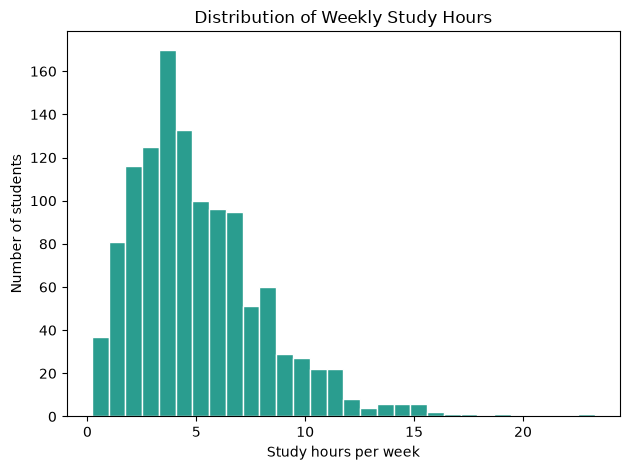

In [7]:
ax = students['study_hours'].plot(kind='hist', bins=30, color='#2A9D8F', edgecolor='white')
ax.set_title('Distribution of Weekly Study Hours')
ax.set_xlabel('Study hours per week')
ax.set_ylabel('Number of students')
plt.tight_layout()
plt.savefig('figures/study_hours_hist.png', dpi=180, bbox_inches='tight')
plt.show()

## Bivariate

In [8]:
numeric_only = ['attendance_rate','study_hours','math','english','science','average_score']
corr = students[numeric_only].corr().round(3)
corr

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.300,0.560,1.000,0.559,0.459,0.814
english,0.327,0.624,0.559,1.000,0.502,0.827
science,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.359,0.704,0.814,0.827,0.815,1.000


In [9]:
print(corr['average_score'].drop('average_score').sort_values(ascending=False))
print('\nGender means')
display(students.groupby('gender')['average_score'].mean().round(2))
print('School type means')
display(students.groupby('school_type')['average_score'].mean().round(2))
print('County means')
display(students.groupby('county')['average_score'].mean().round(2).sort_values(ascending=False))

english            0.827
science            0.815
math               0.814
study_hours        0.704
attendance_rate    0.359
Name: average_score, dtype: float64

Gender means


gender
F    72.10
M    71.91
Name: average_score, dtype: float64

School type means


school_type
Private    76.01
Public     70.46
Name: average_score, dtype: float64

County means


county
Kisumu     73.07
Mombasa    72.17
Nairobi    71.96
Nyeri      71.94
Nakuru     71.84
Turkana    70.97
Name: average_score, dtype: float64

At-risk share by county


performance_band,At Risk,Meeting,Exceeding
county,,,
Nairobi,9.2,55.4,35.3
Mombasa,9.0,54.2,36.8
Nyeri,8.9,54.7,36.5
Kisumu,8.2,50.5,41.3
Turkana,7.9,59.7,32.5
Nakuru,6.4,61.9,31.7


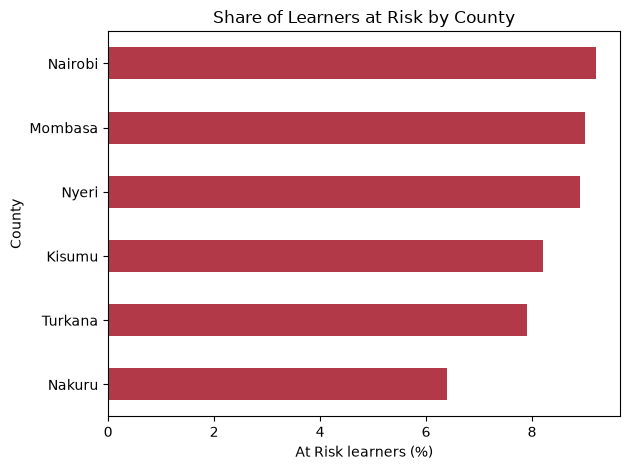

In [10]:
band_ct = pd.crosstab(students['county'], students['performance_band'], normalize='index').mul(100).round(1)
print('At-risk share by county')
display(band_ct.sort_values('At Risk', ascending=False))
ax = band_ct['At Risk'].sort_values().plot(kind='barh', color='#B23A48')
ax.set_title('Share of Learners at Risk by County')
ax.set_xlabel('At Risk learners (%)')
ax.set_ylabel('County')
plt.tight_layout()
plt.savefig('figures/at_risk_by_county.png', dpi=180, bbox_inches='tight')
plt.show()

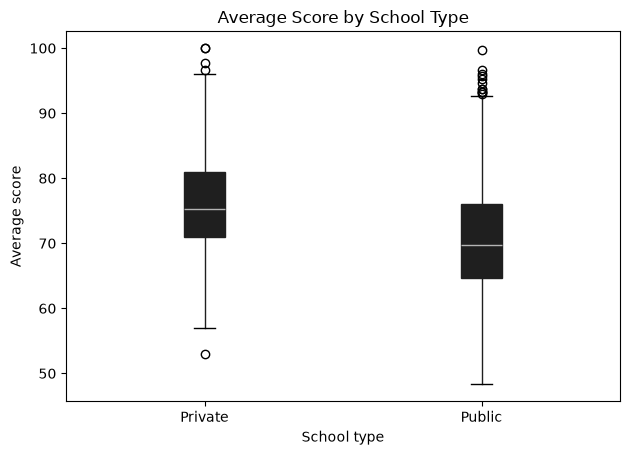

In [11]:
ax = students.boxplot(column='average_score', by='school_type', grid=False, patch_artist=True)
plt.title('Average Score by School Type')
plt.suptitle('')
ax.set_xlabel('School type')
ax.set_ylabel('Average score')
plt.tight_layout()
plt.savefig('figures/score_by_school_type.png', dpi=180, bbox_inches='tight')
plt.show()

## Multivariate

In [12]:
students['attendance_band'] = pd.cut(students['attendance_rate'], bins=[0,.70,.85,1.01], right=False, labels=['Low (<70%)','Medium (70-85%)','High (85-100%)'])
students['study_quartile'] = pd.qcut(students['study_hours'], q=4, labels=['Q1 Lowest','Q2','Q3','Q4 Highest'])
attendance_pivot = pd.pivot_table(students, index='attendance_band', columns='school_type', values='average_score', aggfunc='mean', observed=True).round(2)
study_pivot = pd.pivot_table(students, index='study_quartile', columns='school_type', values='average_score', aggfunc='mean', observed=True).round(2)
print('Attendance-band pivot')
display(attendance_pivot)
print('Study-hour quartile pivot')
display(study_pivot)

Attendance-band pivot


school_type,Private,Public
attendance_band,,
Low (<70%),71.05,64.85
Medium (70-85%),75.60,69.25
High (85-100%),78.65,73.93


Study-hour quartile pivot


school_type,Private,Public
study_quartile,,
Q1 Lowest,69.51,63.82
Q2,74.92,67.12
Q3,76.18,71.18
Q4 Highest,83.65,80.06


## Hypotheses

Slope: 2.117 marks per study hour
R squared: 0.495


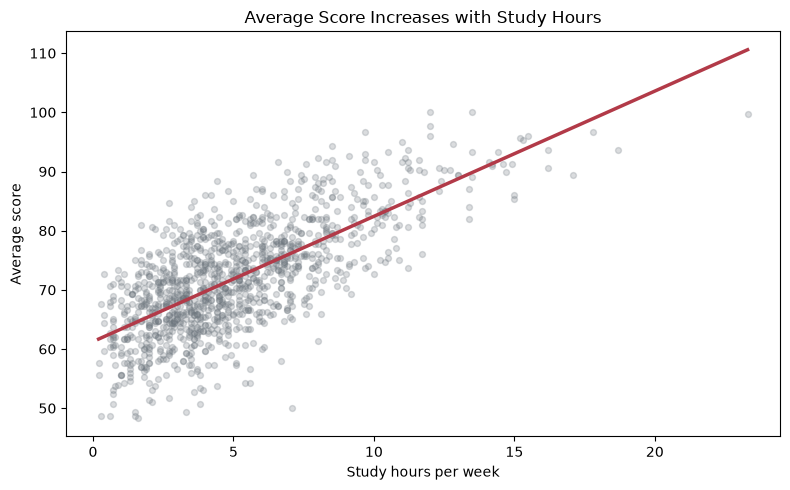

In [13]:
x = students['study_hours'].values
y = students['average_score'].values
slope, intercept = np.polyfit(x,y,1)
fit = stats.linregress(x,y)
print(f'Slope: {slope:.3f} marks per study hour')
print(f'R squared: {fit.rvalue**2:.3f}')
plt.figure(figsize=(8,5))
plt.scatter(x,y,alpha=.25,color='#6C757D',s=18)
line = slope*x+intercept
plt.plot(np.sort(x), slope*np.sort(x)+intercept, color='#B23A48', linewidth=2.5)
plt.title('Average Score Increases with Study Hours')
plt.xlabel('Study hours per week')
plt.ylabel('Average score')
plt.tight_layout()
plt.savefig('figures/study_hours_regression.png',dpi=180,bbox_inches='tight')
plt.show()

### Findings

Five key insights:
1. Attendance and study hours show positive associations with average score.
2. Private-school learners have a higher mean average_score in the sample.
3. County differences reveal uneven learner risk.
4. The school-type gap persists in the attendance and study-hour pivots.
5. Study behaviour explains only part of achievement, as shown by the regression R-squared.

### Recommendations
1. Target learners in the At Risk band and low-attendance group first.
2. Prioritise study-hour support and county-specific learner programmes.

### Limitations
These results are associations, not causal effects. The dataset is cross-sectional and lacks prior attainment, household circumstances, teaching quality and school resources, so a higher study-hour or private-school association should not be interpreted as proof of impact.

In [14]:
students.to_csv('reports/student_performance_enriched.csv', index=False)
print('Student EDA completed; three charts saved to figures/.')

Student EDA completed; three charts saved to figures/.
